# 10. Cards for every season (2021-22 to 2025-26)

Notebook 08 built the full card table for 2025-26 only. `player_card.build_season_cards` packages the same steps (WAR v0.4, card metrics, percentiles, NHL EDGE, age and draft) so they can run on any season. It also merges win probability added (WPA), expected WPA, and Clutch from `data/wpa_by_season.csv` (notebook 13, run it first).

This notebook:
1. downloads NHL EDGE data for 2021-22 to 2024-25 (saved files are skipped, so it can be stopped and rerun)
2. downloads NHL profiles for any player not saved yet
3. builds each season's full card table
4. checks that the rebuilt 2025-26 table matches the saved one on every card column
5. writes one combined slim table for the app, `app_data/cards.csv`
6. prints a few sanity checks
7. checks Takeaway share (the rated row that replaced giveaways)
8. redraws the README card (with the shot map)
9. checks the Clutch rows

`season` is MoneyPuck's start year: 2025 = 2025-26. The app displays `season_label`, never the integer.

## Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

sys.path.append("../src")
from war_model import run_season, V04_PARAMS
from edge_data import download_season, download_bios
from player_card import build_season_cards, export_app_table, app_columns, season_label

DATA = Path("../data")
APP_DATA = Path("../app_data")
BIO_DIR = DATA / "bio_raw"                 # player profiles, not season-specific
REFERENCE = DATA / "cards_2025-26.csv"     # fixed reference for the regression check; never overwritten
WPA = pd.read_csv(DATA / "wpa_by_season.csv")   # WPA, xWPA, Clutch per player-season (notebook 13)

SEASONS = [2021, 2022, 2023, 2024, 2025]   # MoneyPuck start years: 2025 = 2025-26
NEW_SEASONS = SEASONS[:-1]                 # 2025-26 is already downloaded (notebook 08)


def skaters_file(season):
    return DATA / f"skaters{season_label(season)[2:]}.csv"     # 2021 -> skaters21-22.csv


def edge_dir(season):
    return DATA / "edge_raw" / season_label(season)            # 2021 -> edge_raw/2021-22

## 1. Download NHL EDGE data

About 3,800 player-seasons, roughly 40 minutes the first time. Each player is saved as its own file, so if this stops, run the cell again and it picks up where it left off.

In [2]:
player_ids = {s: run_season(skaters_file(s), V04_PARAMS)["playerId"].tolist() for s in SEASONS}

for s in NEW_SEASONS:
    print(f"\n{season_label(s)}: {len(player_ids[s])} skaters")
    download_season(player_ids[s], f"{s}{s + 1}", edge_dir(s))


2021-22: 1003 skaters
1003 already saved, 0 to download (about 0 minutes)
Done, no failures.

2022-23: 951 skaters
951 already saved, 0 to download (about 0 minutes)
Done, no failures.

2023-24: 924 skaters
924 already saved, 0 to download (about 0 minutes)
Done, no failures.

2024-25: 920 skaters
920 already saved, 0 to download (about 0 minutes)
Done, no failures.


## 2. Download player profiles (age and draft)

Profiles aren't season-specific, so only players not saved yet are downloaded.

In [3]:
all_ids = sorted(set().union(*player_ids.values()))
print(len(all_ids), "different players across the five seasons")
failed_bios = download_bios(all_ids, BIO_DIR)

1480 different players across the five seasons
1480 already saved, 0 to download (about 0 minutes)
Done, no failures.


## 3. Build each season's card table

The four older seasons are saved to `data/cards_<label>.csv` (gitignored). 2025-26 is checked in step 4 before anything is saved.

In [4]:
for s in SEASONS:
    n_files = len(list(edge_dir(s).glob("*.json")))
    assert n_files >= len(player_ids[s]), f"{season_label(s)}: only {n_files} of {len(player_ids[s])} EDGE files. Rerun step 1."

cards = {s: build_season_cards(skaters_file(s), edge_dir(s), BIO_DIR, WPA) for s in SEASONS}

for s in NEW_SEASONS:
    path = DATA / f"cards_{season_label(s)}.csv"
    cards[s].to_csv(path, index=False)
    print(f"{season_label(s)}: {len(cards[s])} players, {int(cards[s]['has_edge'].sum())} with EDGE data -> data/{path.name}")

2021-22: 1003 players, 1001 with EDGE data -> data/cards_2021-22.csv
2022-23: 951 players, 950 with EDGE data -> data/cards_2022-23.csv
2023-24: 924 players, 924 with EDGE data -> data/cards_2023-24.csv
2024-25: 920 players, 918 with EDGE data -> data/cards_2024-25.csv


## 4. Regression check: rebuilt 2025-26 vs. the saved reference

`data/cards_2025-26.csv` (from notebook 08) is the fixed reference and is never overwritten. Every column in both tables must match: numbers within 1e-9, text and True/False exactly. If anything differs, the `assert` stops here and nothing is saved.

The only exceptions are an explicit list of columns changed on purpose:
- `pct_take_60`, `pct_give_60`: takeaways and giveaways are now gray "style" rows, because they mostly track puck possession
- `take_share`, `pct_take_share`: the new Takeaway share row (not in the reference)
- `wpa`, `xwpa`, `clutch` and their `pct_` columns: the Clutch section (not in the reference)

In [5]:
def differences(ref, new, cols):
    """Columns where ref and new disagree, with up to 3 example playerIds each."""
    a = ref.set_index("playerId").sort_index()
    b = new.set_index("playerId").sort_index()
    out = {}
    for c in cols:
        x, y = a[c], b[c]
        numeric = pd.api.types.is_numeric_dtype(x) and pd.api.types.is_numeric_dtype(y) and not pd.api.types.is_bool_dtype(x)
        if numeric:
            same = np.isclose(x.astype(float), y.astype(float), rtol=0, atol=1e-9, equal_nan=True)
        else:
            same = np.asarray((x == y) | (x.isna() & y.isna()))
        if not same.all():
            out[c] = a.index[~same][:3].tolist()
    return out


CHANGED_BEFORE = ["pct_take_60", "pct_give_60"]       # takeaway change: already differ from the fixed reference
NEW_BEFORE = ["take_share", "pct_take_share"]         # takeaway change: not in the reference
NEW_NOW = ["wpa", "pct_wpa", "xwpa", "pct_xwpa", "clutch", "pct_clutch"]   # Clutch section: not in the reference
CHANGED = CHANGED_BEFORE
NEW = NEW_BEFORE + NEW_NOW
print("Excluded from the check (changed on purpose):")
print("  earlier takeaway change:", CHANGED_BEFORE + NEW_BEFORE)
print("  this change (Clutch section):", NEW_NOW)

reference = pd.read_csv(REFERENCE)
rebuilt = cards[2025]
assert set(reference["playerId"]) == set(rebuilt["playerId"]), "Rebuilt 2025-26 has different players than the reference"
assert all(c not in reference.columns and c in rebuilt.columns for c in NEW), "New columns should exist only in the rebuilt table"

shared = [c for c in reference.columns if c in rebuilt.columns and c != "playerId" and c not in CHANGED]
bad = differences(reference, rebuilt, shared)
assert not bad, f"Rebuilt 2025-26 does not match the reference on: {bad}"
print(f"Regression check passed: all {len(shared)} other shared columns match for {len(rebuilt)} players.")

ref_by_id = reference.set_index("playerId")
new_by_id = rebuilt.set_index("playerId").loc[ref_by_id.index]
for c in CHANGED:
    n = int((~np.isclose(ref_by_id[c], new_by_id[c], equal_nan=True)).sum())
    print(f"  {c}: {n} players differ (on purpose)")

rebuilt.to_csv(DATA / "cards_2025-26_v2.csv", index=False)
print("Saved data/cards_2025-26_v2.csv. The reference file was not changed.")

Excluded from the check (changed on purpose):
  earlier takeaway change: ['pct_take_60', 'pct_give_60', 'take_share', 'pct_take_share']
  this change (Clutch section): ['wpa', 'pct_wpa', 'xwpa', 'pct_xwpa', 'clutch', 'pct_clutch']
Regression check passed: all 150 other shared columns match for 940 players.
  pct_take_60: 0 players differ (on purpose)
  pct_give_60: 932 players differ (on purpose)
Saved data/cards_2025-26_v2.csv. The reference file was not changed.


## 5. Combined slim table for the app

One row per player per season, only the columns the card draws plus `season` and `season_label`. Built from the tables in memory above.

In [6]:
combined = pd.concat([cards[s] for s in SEASONS], ignore_index=True)
slim = export_app_table(combined, APP_DATA / "cards.csv", by_season=True)

# No raw MoneyPuck situation columns, except ev_rel_xga_60 (shown on the card)
raw = [c for c in slim.columns if c.startswith(("ev_", "pp_", "pk_", "all_")) and c != "ev_rel_xga_60"]
assert not raw, f"Raw situation columns in slim table: {raw}"

# Hidden card rows are left out
assert "oz_pct_ev" not in slim.columns and "pct_oz_pct_ev" not in slim.columns

# One row per player per season, the expected columns, all five seasons
assert not slim.duplicated(["playerId", "season"]).any(), "A player appears twice in one season"
assert list(slim.columns) == app_columns(by_season=True)
assert sorted(slim["season"].unique()) == SEASONS

print("All checks passed.", slim.shape, "-> app_data/cards.csv")

All checks passed. (4738, 67) -> app_data/cards.csv


## 6. Sanity checks

In [7]:
print(slim.groupby("season_label").size().rename("player-seasons").to_string())

show = ["season_label", "team", "games_played", "war"]
for name in ["Connor McDavid", "Macklin Celebrini"]:
    print(f"\n{name}")
    print(slim[slim["name"] == name][show].round(2).to_string(index=False))

assert sorted(slim.loc[slim["name"] == "Connor McDavid", "season"]) == SEASONS, "McDavid should have all five seasons"
assert sorted(slim.loc[slim["name"] == "Macklin Celebrini", "season"]) == [2024, 2025], "Celebrini should have 2024-25 and 2025-26 only"

season_label
2021-22    1003
2022-23     951
2023-24     924
2024-25     920
2025-26     940

Connor McDavid
season_label team  games_played  war
     2021-22  EDM            80 6.06
     2022-23  EDM            82 8.74
     2023-24  EDM            76 5.99
     2024-25  EDM            67 4.56
     2025-26  EDM            82 6.12

Macklin Celebrini
season_label team  games_played  war
     2024-25  SJS            70 2.51
     2025-26  SJS            82 4.71


## 7. Takeaway share checks

Raw giveaways rise with puck possession, so stars ranked near the bottom. Takeaway share (takeaways / (takeaways + giveaways), 5v5) should not depend on how much a player has the puck, so its correlation with points should be near zero. Seasons before 2024-25 are shown separately, because takeaways and giveaways were recorded differently then.

In [8]:
from player_card import FIRST_CLEAN_TRACKING_SEASON
from compare import ordinal

qual_f = slim[slim["qualified"] & (slim["pos_group"] == "F")]
eras = {"2021-24": qual_f["season"] < FIRST_CLEAN_TRACKING_SEASON,
        "2024-26": qual_f["season"] >= FIRST_CLEAN_TRACKING_SEASON}
print("Correlation with 5v5 points per 60, qualified forwards")
for era, in_era in eras.items():
    g = qual_f[in_era]
    print(f"  {era}: Takeaway share r = {g['take_share'].corr(g['pts_60']):+.2f}   "
          f"giveaways r = {g['give_60'].corr(g['pts_60']):+.2f}   (n = {len(g)})")

show = ["name", "team", "take_60", "give_60", "take_share", "pts_60"]
f26 = qual_f[qual_f["season"] == 2025].dropna(subset=["take_share"])
print("\nTop 10 qualified forwards by Takeaway share, 2025-26")
print(f26.nlargest(10, "take_share")[show].round(3).to_string(index=False))
print("\nBottom 10 qualified forwards by Takeaway share, 2025-26")
print(f26.nsmallest(10, "take_share")[show].round(3).to_string(index=False))

print("\nOld giveaway percentile (reference) vs. new Takeaway share percentile, 2025-26")
old = reference.set_index("playerId")["pct_give_60"]
for name in ["Connor McDavid", "Macklin Celebrini"]:
    r = slim[(slim["name"] == name) & (slim["season"] == 2025)].iloc[0]
    print(f"  {name}: giveaways {ordinal(old[r['playerId']])}  ->  Takeaway share {ordinal(r['pct_take_share'])} ({r['take_share']:.0%})")

Correlation with 5v5 points per 60, qualified forwards
  2021-24: Takeaway share r = -0.07   giveaways r = +0.38   (n = 1398)
  2024-26: Takeaway share r = +0.02   giveaways r = +0.35   (n = 921)

Top 10 qualified forwards by Takeaway share, 2025-26
             name team  take_60  give_60  take_share  pts_60
 Jaroslav Chmelar  NYR    1.419    0.946       0.600   1.419
   Brendan Gaunce  CBJ    1.452    1.210       0.545   0.968
Justin Hryckowian  DAL    1.592    1.393       0.533   1.659
    Ryan O'Reilly  NSH    1.876    2.028       0.481   2.129
        Josh Doan  BUF    2.560    3.025       0.458   1.920
        Tim Washe  ANA    1.390    1.699       0.450   0.772
      Radek Faksa  DAL    1.428    1.868       0.433   1.428
  William Carrier  CAR    1.053    1.458       0.419   1.458
    Rodrigo Abols  PHI    1.468    2.056       0.417   1.175
       Tyson Jost  NSH    1.757    2.476       0.415   1.038

Bottom 10 qualified forwards by Takeaway share, 2025-26
             name team

## 8. README card

Redraw Seider's 2025-26 card from the app tables, with his shot map (notebook 12), so the README image matches the app.

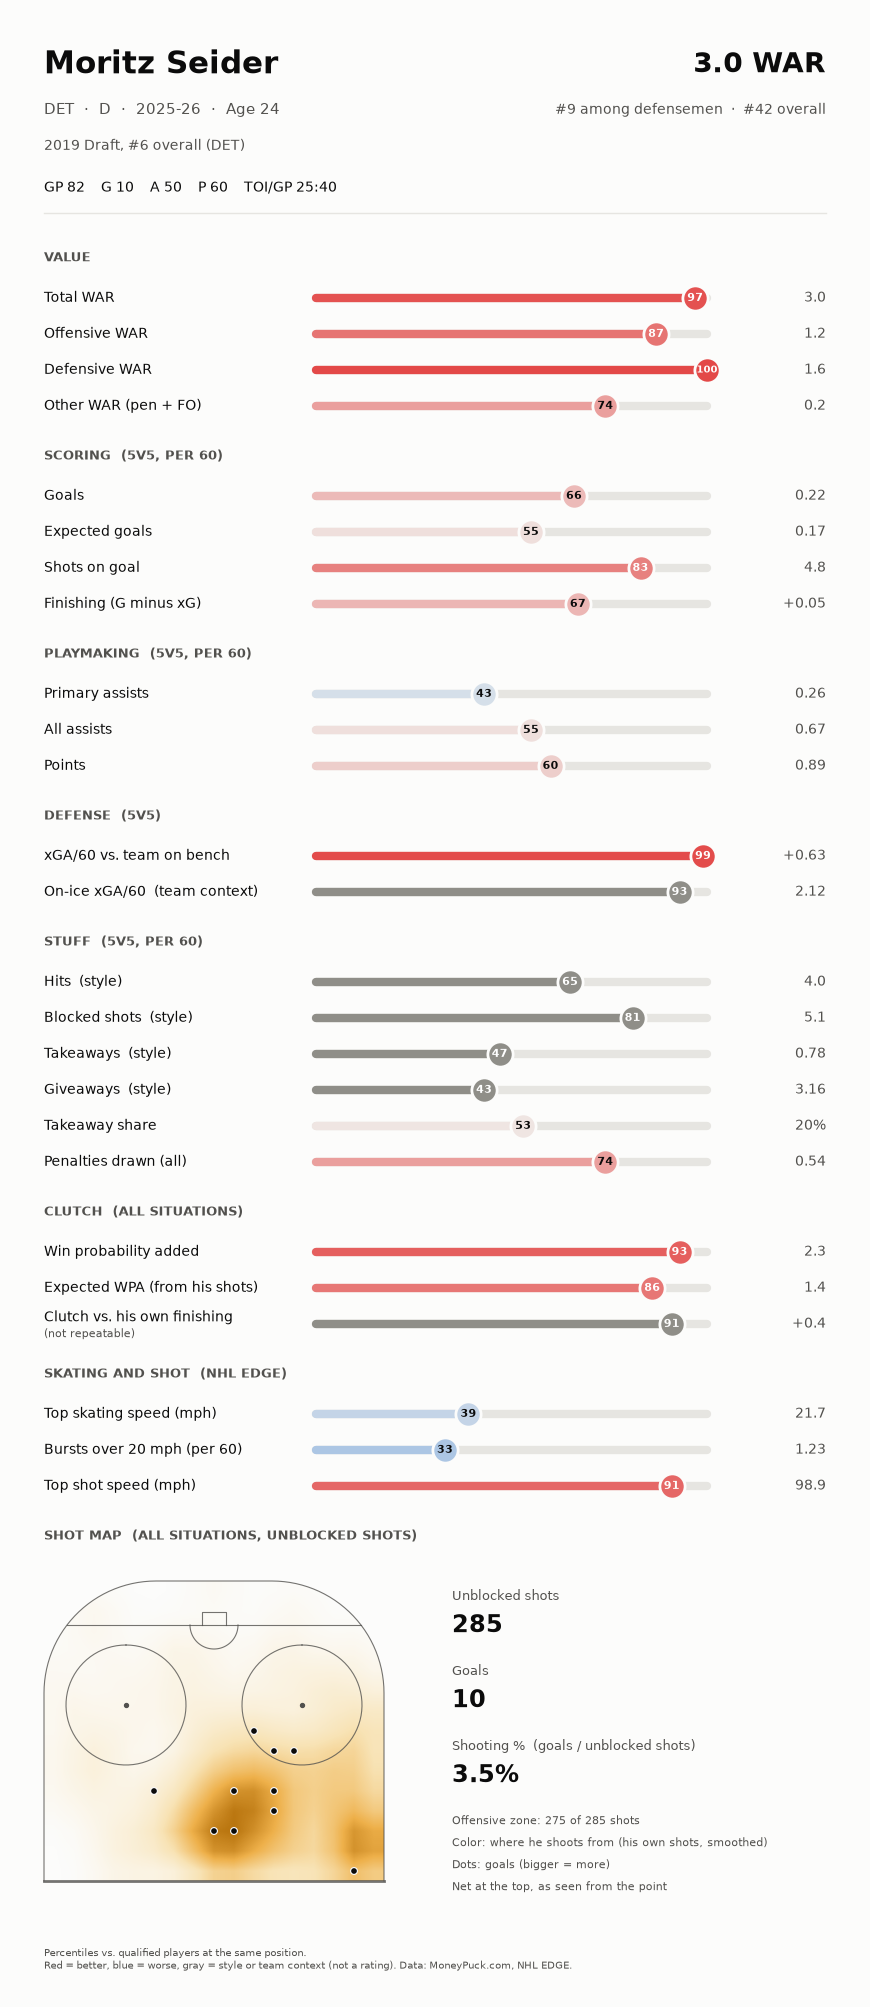

In [9]:
from player_card import draw_card

KEY = ["playerId", "season"]
app = pd.read_csv(APP_DATA / "cards.csv").merge(pd.read_csv(APP_DATA / "shot_totals.csv"), on=KEY, how="left")
grid = pd.read_csv(APP_DATA / "shot_grid.csv")
seider = app[(app["name"] == "Moritz Seider") & (app["season"] == 2025)].iloc[0]
seider_grid = grid[(grid["playerId"] == seider["playerId"]) & (grid["season"] == 2025)][["gx", "gy", "shots", "goals"]]
draw_card(seider, seider["season_label"], shot_grid=seider_grid.reset_index(drop=True),
          path=Path("../images/cards/seider_2025-26.png"));

## 9. Clutch checks

The Clutch section comes from notebook 13: win probability added (WPA) and expected WPA (xWPA) are rated, because they repeat from season to season; Clutch vs. his own finishing is gray, because it doesn't. Clutch is blank under 100 unblocked shots.

In [10]:
show = ["name", "team", "position", "goals", "wpa", "pct_wpa", "xwpa", "pct_xwpa"]
s26 = slim[slim["season"] == 2025]
for col, title in [("wpa", "WPA"), ("xwpa", "xWPA")]:
    print(f"Top 10 by {title}, 2025-26 (percentiles within position, vs. qualified players)")
    print(s26.nlargest(10, col)[show].round(2).to_string(index=False))
    print()

print("Clutch rows")
clutch_cols = ["name", "season_label", "goals", "wpa", "xwpa", "clutch", "pct_clutch"]
picks = [("Alex Ovechkin", 2021), ("Connor McDavid", 2022), ("Macklin Celebrini", 2025)]
rows = pd.concat([slim[(slim["name"] == n) & (slim["season"] == s)] for n, s in picks])
rows = rows.merge(WPA[["playerId", "season", "unblocked_shots"]], on=["playerId", "season"], how="left")
print(rows[["name", "season_label", "unblocked_shots", "goals", "wpa", "xwpa", "clutch", "pct_clutch"]].round(2).to_string(index=False))
print(f"\nClutch blank (under 100 unblocked shots): {int(slim['clutch'].isna().sum()):,} of {len(slim):,} player-seasons")

Top 10 by WPA, 2025-26 (percentiles within position, vs. qualified players)
             name team position  goals   wpa  pct_wpa  xwpa  pct_xwpa
    Cole Caufield  MTL        R   51.0 11.38    100.0  6.65     100.0
   Steven Stamkos  NSH        C   42.0  8.28    100.0  4.81      93.0
   Alex DeBrincat  DET        R   41.0  7.95     99.0  6.56      99.0
 Nathan MacKinnon  COL        C   53.0  7.82     99.0  5.93      98.0
  Kirill Kaprizov  MIN        L   45.0  7.78     99.0  5.91      98.0
   Dylan Guenther  UTA        R   40.0  7.56     99.0  4.76      92.0
     Adrian Kempe  LAK        R   36.0  7.56     99.0  5.19      95.0
    Morgan Geekie  BOS        C   39.0  7.53     98.0  3.97      85.0
  Cutter Gauthier  ANA        L   41.0  7.38     98.0  5.24      96.0
Macklin Celebrini  SJS        C   45.0  7.35     98.0  5.27      97.0

Top 10 by xWPA, 2025-26 (percentiles within position, vs. qualified players)
           name team position  goals   wpa  pct_wpa  xwpa  pct_xwpa
 Connor 